# Analysis of membrane sweeling and cracking based on ML segmentation

TODO:
    
- [x] load EC data
- [x] load segmented data
- [x] fetch physical time of images from registered data
- [ ] segment all samples
- [ ] define cropping for each sample
    - registered data as refrence
    - look up cropping for segmentation
    - [x] update ML code to include this cropping [:, 250:-250, 50:-50] was used for membrane of sample 3II
- [ ] find useful metric
    - [ ] delaminated area
    - [ ] crack volume
    - [ ] membrane volume
    - [ ] vs. charge, current
    - [ ] normalized metric
- [ ] continue from there

In [1]:
# modules

import json
import os
import socket
host = socket.gethostname()   
import scipy as sp
import scipy.ndimage
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import cupy as cp
import cucim
import warnings
import skimage.morphology

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path = os.path.join(toppathSSD, '02_registered_3p1D')

px = 2.75e-6
vx = px**3

## Experiment with data

In [2]:
sample = '3II'
segpath = os.path.join(segmentation_path, sample, 'final_seg.nc')
seg_data = xr.load_dataset(segpath)

In [3]:
regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)


In [4]:
t_utc_tomo = reg_data['t_utc'].data

In [5]:
reg_data.close()

### crop the volume to exclude borders with errors

In [6]:
im = seg_data['segmented'].sel(time = 62)

In [7]:
# # crop = 50 for a,b seems reasonable


# crops = np.arange(0, 300, 20)
# volume = np.zeros(len(crops))
# im_size = volume.copy()

# for i in  range(len(crops)):
#     crop = crops[i]
#     a = 0+crop
#     b = im.shape[0]-crop
#     c = 0
#     d = im.shape[1]
#     e = 0 + crop
#     f = im.shape[2]-crop
    
#     volume[i] = np.count_nonzero(im[a:b,c:d,e:f]==0)
#     im_size[i] = (b-a)*(d-c)*(f-e)


In [8]:
# volume_old = volume.copy()
# im_size_old = im_size.copy()
# crops_old = np.arange(/0,200,10)

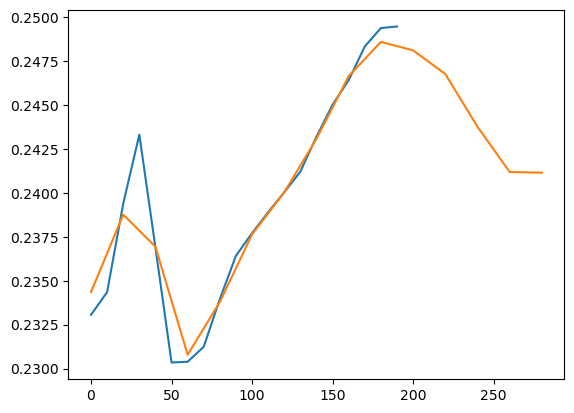

In [38]:
plt.plot(crops, np.gradient(volume)/np.gradient(im_size))

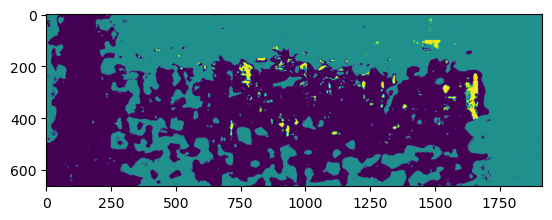

In [43]:
plt.imshow(im[50:-50,100,:])

In [95]:
reg_im = reg_data[list(reg_data.keys())[-1]].data

In [85]:
reg_data.close()

In [12]:
cropx = 50  #:, 250:-250, 50:-50]

# initial cropping from registered data to segmented data
# for the other samples, get this information from the seg_data
ar = 0
br = 0
cr = 250
dr = -250+1
er = 50
fr = -50

a1 = cropx
b1 = -cropx
c1 = 0
d1 = -1
e1 = 150
f1 = -250

a = a1 + ar
b = b1 + br
c = c1 + cr
d = d1 + dr
e = e1 + er 
f = f1 + fr

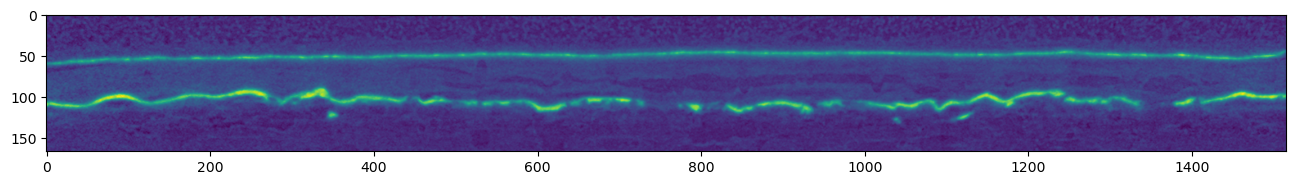

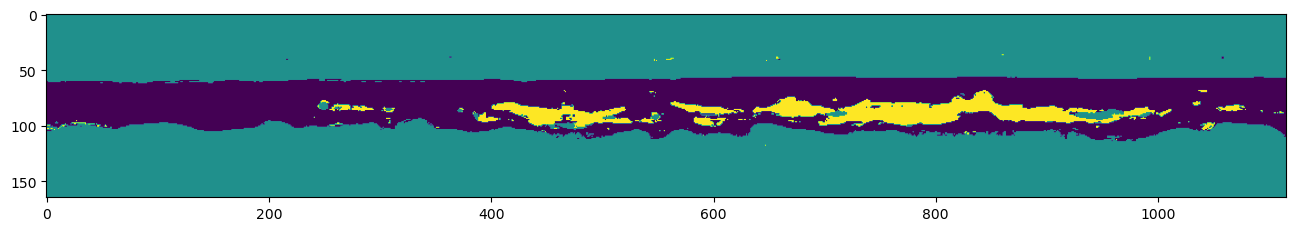

In [122]:
plt.figure(figsize=(16,9))
plt.imshow(reg_im[a+200,c:d,e:f])
plt.figure(figsize=(16,9))
plt.imshow(im[a1+200,c1:d1,e1:f1])

### use morphology operation to remove segmentation noise

In [8]:
membrane_im = im[a1:b1,c1:d1,e1:f1]==0
crack_im = im[a1:b1,c1:d1,e1:f1]==2

In [9]:
def clean_binary_image(im, minsize = 200, fp_radius = 1, i=0, GPU = True):
    # GPU?
    if GPU:
        warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!   
        gpu_id = i%5 # i%4+1 uses gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5

        with cp.cuda.Device(gpu_id):
            im = cp.array(im)
            im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(fp_radius))
            im = cucim.skimage.morphology.remove_small_objects(im, min_size=minsize)
            im = cp.asnumpy(im)
            mempool = cp.get_default_memory_pool()
            mempool.free_all_blocks()
        
    else: 
        im = sp.ndimage.binary_opening(im, structure=skimage.morphology.ball(fp_radius))
        im = skimage.morphology.remove_small_objects(im, min_size=minsize)
        
    return im


def clean_and_count_binary_image(im, minsize = 200, fp_radius = 1, i=0, GPU = True):
    # GPU?
    if GPU:
        warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!   
        gpu_id = i%5 # i%4+1 uses gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5

        with cp.cuda.Device(gpu_id):
            im = cp.array(im)
            im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(fp_radius))
            im = cucim.skimage.morphology.remove_small_objects(im, min_size=minsize)
            count = cp.count_nonzero(im)
            count = cp.asnumpy(count) #that necessary?
            im = cp.asnumpy(im)
            mempool = cp.get_default_memory_pool()
            mempool.free_all_blocks()
        
    else: 
        im = sp.ndimage.binary_opening(im, structure=skimage.morphology.ball(fp_radius))
        im = skimage.morphology.remove_small_objects(im, min_size=minsize)
        count = np.count_nonzero(im)
        
    return im, count

### extract volumes of crack and membrane
compare in second step to "cleaned" images

In [10]:
def clean_4D_image(im4D, minsize = 200, fp_radius = 1, GPU = True):
    results = Parallel(n_jobs = 10)(delayed(clean_binary_image)(im4D[:,:,:,i], minsize, fp_radius,i, GPU) for i in range(im4D.shape[3]))
    clean4D = np.stack(results, axis=3)
    return clean4D

def clean_and_count_4D_image(im4D, minsize = 200, fp_radius = 1, GPU = True):
    results = Parallel(n_jobs = 10)(delayed(clean_and_count_binary_image)(im4D[:,:,:,i], minsize, fp_radius,i, GPU) for i in range(im4D.shape[3]))
    vols = [result[1] for result in results]
    ims = [result[0] for result in results]
    clean4D = np.stack(ims, axis=3)
    vols = np.stack(vols)
    return clean4D, vols


def extract_membrane_and_crack_volume(seg_data, clean =False):
    membrane = seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==0
    crack = seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==2
    
    if clean:
        print('clean up segmentation errors')
        
    else:
        print('do not clean up segmentation errors')
    #optional: clean
    
    membrane_vol = np.count_nonzero(membrane, axis=(0,1,2))
    crack_vol = np.count_nonzero(crack, axis=(0,1,2))
    return membrane_vol, crack_vol



In [13]:
mem_clean, mem_vol_clean = clean_and_count_4D_image(seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==0)

In [14]:
crack_clean, crack_vol_clean = clean_and_count_4D_image(seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==2)

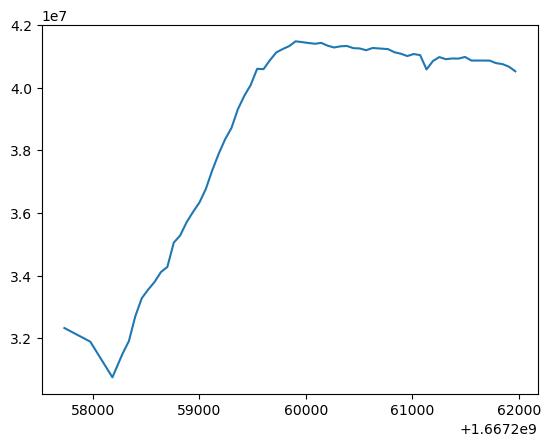

In [15]:
plt.plot(t_utc_tomo, mem_vol_clean)
# plt.plot(t_utc_tomo, crack_vol_clean+mem_vol_clean)

### load EC and compare

In [16]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    # print(dims)
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()
    # print(len(dims))

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['Re(Z)'].data
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    # print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    # print(timestamps[0])
    
#     filter out potential overflow cases
    I = I[E>-5]
    Im = Im[E>-5]
    Re = Re[E>-5]
    timestamps = timestamps[E>-5]
    E = E[E>-5]
    
    time = timestamps - t0
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps, t0

In [17]:
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)

In [18]:
Qfun = sp.interpolate.interp1d(timestamps, Q, fill_value=np.nan, bounds_error=False)
Ifun = sp.interpolate.interp1d(timestamps, I, fill_value=np.nan, bounds_error=False)

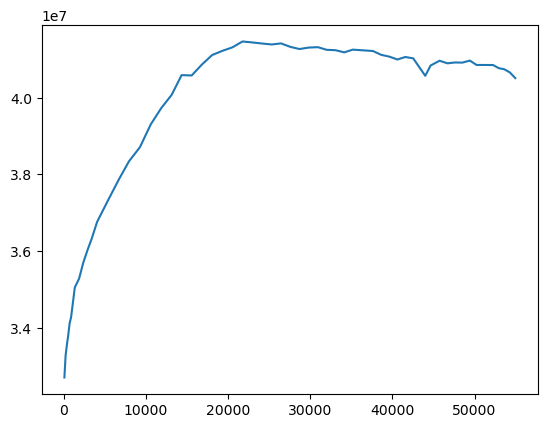

In [19]:
plt.plot(Qfun(t_utc_tomo), mem_vol_clean)

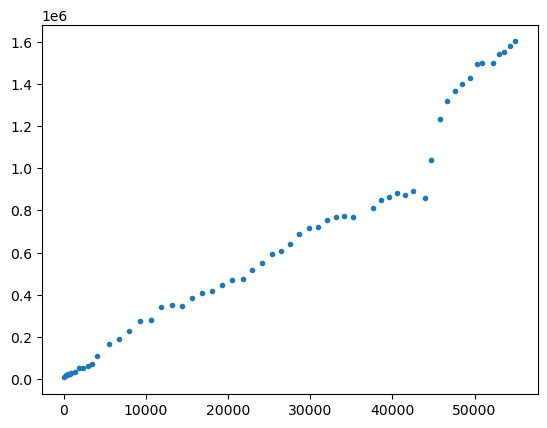

In [20]:
plt.plot(Qfun(t_utc_tomo), crack_vol_clean, '.')

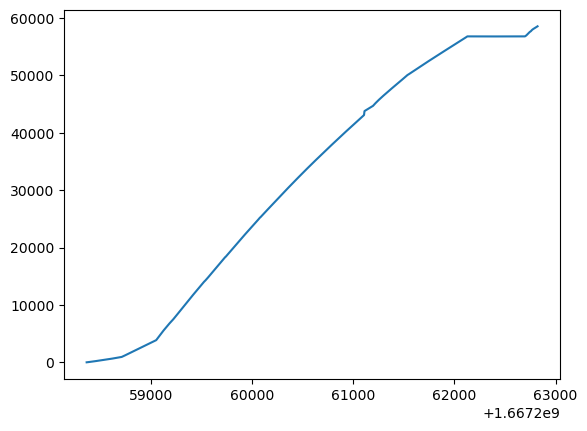

In [21]:
plt.plot(timestamps, Q)

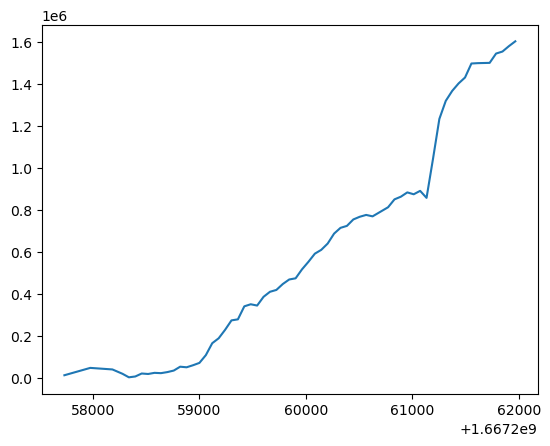

In [22]:
plt.plot(t_utc_tomo, crack_vol_clean)

(40500000.0, 42000000.0)

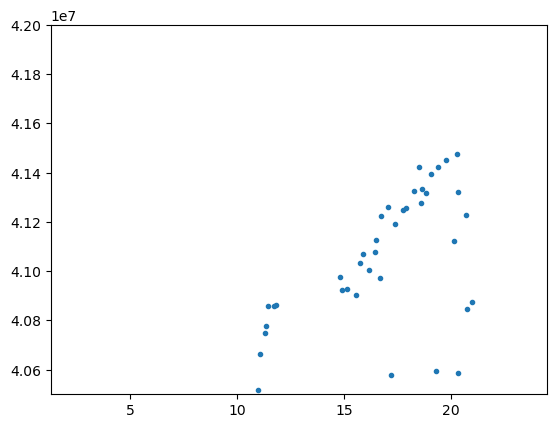

In [46]:
plt.plot(-Ifun(t_utc_tomo), mem_vol_clean, '.')
plt.ylim(4.05e7,4.2e7)

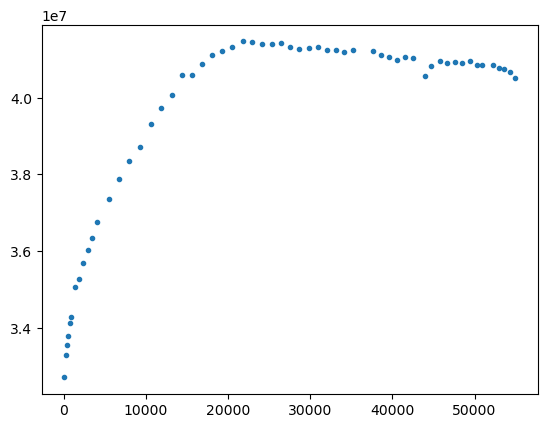

In [48]:
plt.plot(Qfun(t_utc_tomo), mem_vol_clean, '.')
# plt.ylim(4.05e7,4.2e7)

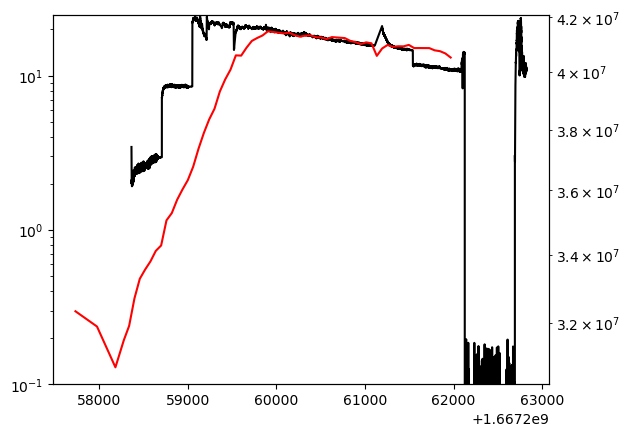

In [56]:
fig, ax = plt.subplots()
ax.plot(timestamps, -I, 'k')
ax2 = ax.twinx()
ax2.plot(t_utc_tomo, mem_vol_clean, 'r')
ax.set_ylim(0.1,25)
# ax2.set_ylim(4.05e7,4.2e7)
ax.set_yscale('log')
ax2.set_yscale('log')

(40500000.0, 42000000.0)

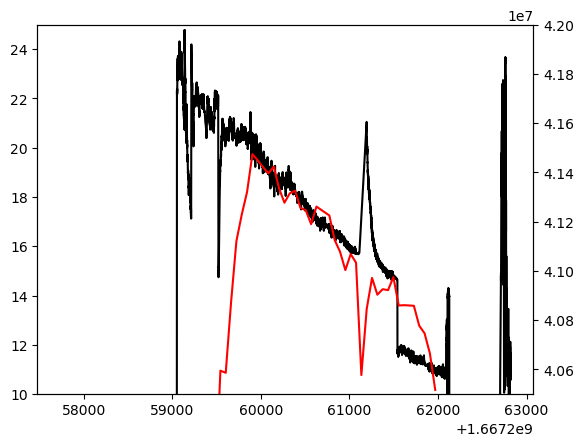

In [50]:
fig, ax = plt.subplots()
ax.plot(timestamps, -I, 'k')
ax2 = ax.twinx()
ax2.plot(t_utc_tomo, mem_vol_clean, 'r')
ax.set_ylim(10,25)
ax2.set_ylim(4.05e7,4.2e7)